<a href="https://colab.research.google.com/github/AnastasiiaBerezovska/ME-350R-Project/blob/main/Team1_synthesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# walking task before the length links
# 70 mm stride and 15 mm lift below are starting values from the class example!!! NOT FINAL
import numpy as np
import matplotlib.pyplot as plt

# DRAFTING of the walking requirements!!!
stride_mm = 70.0
minimum_lift_mm = 15.0
stance_angle_deg = 180.0
motor_rpm = 24.0


# One crank revolution produces one leg cycle
cycle_time_s = 60.0/motor_rpm
stance_time_s = cycle_time_s * stance_angle_deg / 360.0

# 7 equally timed targets during ground contact
crank_travel_deg = np.linspace(0, stance_angle_deg, 7)

# relative to the body, the planted foot moves backward
target_x_mm = (stride_mm / 2- stride_mm * crank_travel_deg / stance_angle_deg)
target_y_mm = np.zeros(7)

targets_mm = np.column_stack((target_x_mm, target_y_mm))

print(f"Cycle time: {cycle_time_s:.2f} seconds")
print(f"Stance time: {stance_time_s:.2f} seconds")
print(f"Required mid-swing lift: {minimum_lift_mm:.1f} mm")

print("\nCrank travel | Target x | Target y")
for angle, (x, y) in zip(crank_travel_deg, targets_mm):
    print(f"{angle:7.1f} deg | {x:7.2f} mm | {y:7.2f} mm")

print("During ground contact, move the foot backward through these positions at these crank intervals!")

Cycle time: 2.50 seconds
Stance time: 1.25 seconds
Required mid-swing lift: 15.0 mm

Crank travel | Target x | Target y
    0.0 deg |   35.00 mm |    0.00 mm
   30.0 deg |   23.33 mm |    0.00 mm
   60.0 deg |   11.67 mm |    0.00 mm
   90.0 deg |    0.00 mm |    0.00 mm
  120.0 deg |  -11.67 mm |    0.00 mm
  150.0 deg |  -23.33 mm |    0.00 mm
  180.0 deg |  -35.00 mm |    0.00 mm
During ground contact, move the foot backward through these positions at these crank intervals!


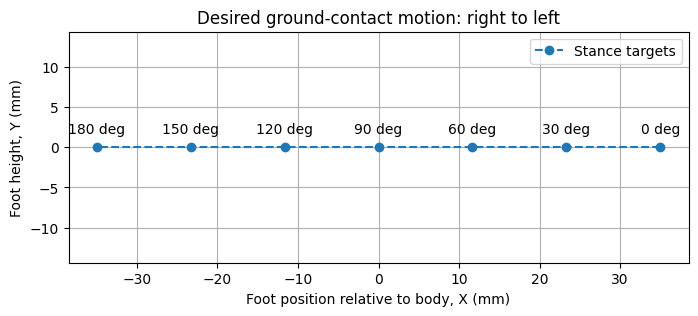

In [ ]:
# desired positions
plt.figure(figsize=(8, 3))

plt.plot(target_x_mm, target_y_mm,"o--",label="Stance targets")

for angle, x, y in zip(crank_travel_deg, target_x_mm, target_y_mm):
    plt.annotate(f"{angle:.0f} deg",(x, y),xytext=(0, 10),textcoords="offset points",ha="center")

plt.xlabel("Foot position relative to body, X (mm)")
plt.ylabel("Foot height, Y (mm)")
plt.title("Desired ground-contact motion: right to left")
plt.ylim(-10, 20)
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
import numpy as np

mm_per_unit = 25.4
crank_radius = 0.80
pivot_dx = -4.45
pivot_dy = 0.45

drawing_lengths = {
    "Oi": crank_radius,
    "ij": 4.554,
    "Aj": 2.200,
    "jk": 3.430,
    "Ak": 2.620,
    "kl": 3.773,
    "Am": 4.059,
    "lm": 2.687,
    "im": 4.926,
    "mn": 2.974,
    "ln": 4.329,
}


required = {"mm_per_unit": mm_per_unit,"crank_radius": crank_radius,"pivot_dx": pivot_dx,"pivot_dy": pivot_dy,}

missing = [
    name for name, value in required.items()
    if value is None
]

if missing:
    raise ValueError("Fill in these values first: " + ", ".join(missing))

lengths_mm = {name: value * mm_per_unit for name, value in drawing_lengths.items()}

# oriin
O_fixed = np.array([0.0, 0.0])


A_fixed = np.array([pivot_dx, pivot_dy]) * mm_per_unit

print("Joint-to-joint dimensions:")
for name, length in lengths_mm.items():
    print(f"{name}: {length:.3f} mm")

print("Motor pivot:", O_fixed, "mm")
print("Other fixed pivot:", A_fixed, "mm")

Joint-to-joint dimensions:
Oi: 20.320 mm
ij: 115.672 mm
Aj: 55.880 mm
jk: 87.122 mm
Ak: 66.548 mm
kl: 95.834 mm
Am: 103.099 mm
lm: 68.250 mm
im: 125.120 mm
mn: 75.540 mm
ln: 109.957 mm
Motor pivot: [0. 0.] mm
Other fixed pivot: [-113.03   11.43] mm


In [ ]:
def joint_from_two_pivots(P, Q, rP, rQ, side):
    """Finding a joint connected to P and Q by two fixed lengths."""
    vector = Q - P
    distance = np.linalg.norm(vector)

    # rejecting the geometry that cannot physically connect.
    if (distance < 1e-10
        or distance > rP + rQ + 1e-8
        or distance < abs(rP - rQ) - 1e-8
    ):
        raise ValueError("These links cannot connect to this angle")

    along = (rP**2 - rQ**2 + distance**2) / (2 * distance)
    height_squared = rP**2 - along**2

    if height_squared < -1e-8:
        raise ValueError("no real joint position.")

    unit = vector / distance
    normal = np.array([-unit[1], unit[0]])

    return (P+ along * unit+ side * np.sqrt(max(0.0,height_squared)) * normal)


def leg_position(angle_deg, L):
    """Calculating all joint positions for one crank angle."""
    theta = np.radians(angle_deg)

    O = O_fixed.copy()
    A = A_fixed.copy()

    # The motor rotates the crank O to i
    i = O + L["Oi"] * np.array([np.cos(theta), np.sin(theta)])

    # solving the remaining joints in order.
    # The signs select which side each joint bends toward.
    j = joint_from_two_pivots(i, A, L["ij"], L["Aj"], -1)
    m = joint_from_two_pivots(i, A, L["im"], L["Am"], +1)
    k = joint_from_two_pivots(j, A, L["jk"], L["Ak"], -1)
    l = joint_from_two_pivots(k, m, L["kl"], L["lm"], -1)
    n = joint_from_two_pivots(l, m, L["ln"], L["mn"], -1)

    return {"O": O, "A": A, "i": i, "j": j,
            "k": k, "l": l, "m": m, "n": n}


# Calculating the mechanism at every degree==>  including the endpoin
angles_deg = np.arange(361)

poses = [leg_position(angle, lengths_mm)for angle in angles_deg]

toe_path_mm = np.array([pose["n"] for pose in poses])

print("Calculated positions from 0 through 360 degrees.")
print(f"Full-path horizontal span: {np.ptp(toe_path_mm[:, 0]):.2f} mm")
print(f"Full-path vertical excursion: {np.ptp(toe_path_mm[:, 1]):.2f} mm")

Calculated positions from 0 through 360 degrees.
Full-path horizontal span: 66.41 mm
Full-path vertical excursion: 25.68 mm


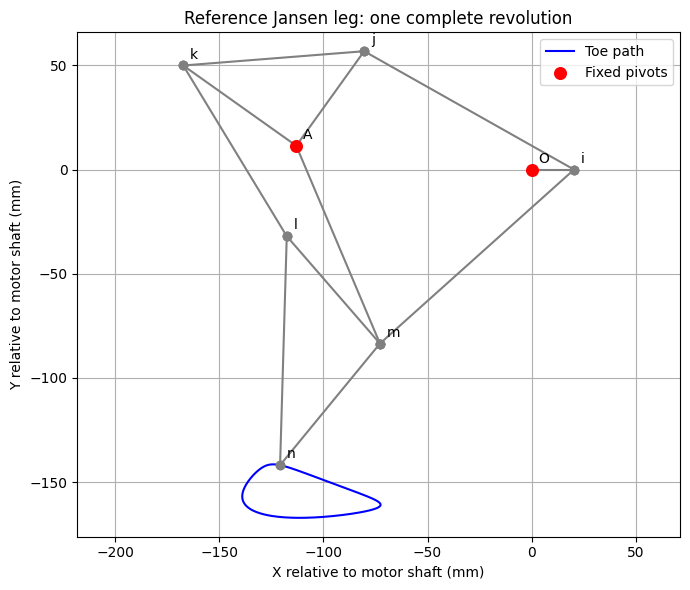

In [ ]:
plt.figure(figsize=(7, 6))

# blue curve is ==> everywhere the toe travels during one revolution
plt.plot(toe_path_mm[:, 0],toe_path_mm[:, 1],"b-",label="Toe path")

# drawing the linkage at its initial crank angle
pose = poses[0]

for connection in lengths_mm:
    P = pose[connection[0]]
    Q = pose[connection[1]]

    plt.plot([P[0], Q[0]],[P[1], Q[1]],"o-",color="gray")

for name, point in pose.items():
    plt.annotate(name, point,xytext=(5, 5),textcoords="offset points")

plt.scatter([O_fixed[0], A_fixed[0]],[O_fixed[1], A_fixed[1]],color="red",s=70,label="Fixed pivots",zorder=5)

plt.xlabel("X relative to motor shaft (mm)")
plt.ylabel("Y relative to motor shaft (mm)")
plt.title("Reference Jansen leg: one complete revolution")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# matching the reference leg to our draft stance targets.
# Clockwise rotation ==> crank angle = starting angle - travel.

best_reference = None

for start_deg in range(360):
    sample = np.array([leg_position(start_deg - travel, lengths_mm)["n"]
        for travel in crank_travel_deg
    ])

    # translating the leg into the target coordinate system
    offset = np.mean(targets_mm - sample,axis=0)
    actual = sample + offset # like arduino

    # rms distance between actual and desired position
    errors = np.linalg.norm(actual - targets_mm,axis=1)
    rms_error = np.sqrt(np.mean(errors**2))

    if (best_reference is None or rms_error < best_reference["rms_error"]):
        best_reference = {
            "start_deg": start_deg,
            "offset": offset,
            "rms_error": rms_error
        }

# checking the entire stance at one deg intervals
stance_travel_deg = np.linspace(0, stance_angle_deg,int(np.ceil(stance_angle_deg)) + 1)

stance_path_mm = np.array([leg_position(best_reference["start_deg"] - travel,lengths_mm)["n"]
    for travel in stance_travel_deg]) + best_reference["offset"]

backward_travel_mm = (stance_path_mm[0, 0] - stance_path_mm[-1, 0])
height_variation_mm = np.ptp(stance_path_mm[:, 1])

print("REFERENCE STUFF - link Length still unchanges!!!")
print(f"Starting crank angle: {best_reference['start_deg']} degrees")
print(f"Target RMS error: {best_reference['rms_error']:.2f} mm")
print(f"Backward travel during stance: {backward_travel_mm:.2f} mm")
print(f"Stance height variation: {height_variation_mm:.2f} mm")

REFERENCE STUFF - link Length still unchanges!!!
Starting crank angle: 106 degrees
Target RMS error: 7.20 mm
Backward travel during stance: 65.38 mm
Stance height variation: 18.48 mm


In [ ]:
# geomtransmission-angle screen
# each entry shoudl identify the joint and its two connected directions.
# The rigid triangles themselves are not included

angle_checks = {
    "j: ij / Aj": ("j", "i", "A"),
    "m: im / Am": ("m", "i", "A"),
    "l: kl / lm": ("l", "k", "m"),
}

angle_results = {}
angle_limit_deg = 40.0  # drafting the screening limit from class

for label, (joint_name, end1, end2) in angle_checks.items():
    measured_angles = []

    for pose in poses:
        v1 = pose[end1] - pose[joint_name]
        v2 = pose[end2] - pose[joint_name]

        cosine = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

        # using the acute angle ==> between 0 and 90 degrees
        acute_angle = np.degrees(np.arccos(np.clip(abs(cosine), 0.0, 1.0)))
        measured_angles.append(acute_angle)

    measured_angles = np.array(measured_angles)
    worst_index = np.argmin(measured_angles)
    minimum_angle = measured_angles[worst_index]

    angle_results[label] = measured_angles

    status = ("PASSES" if minimum_angle >= angle_limit_deg else "FAILS")

    print(f"{label}: minimum = {minimum_angle:.2f} degrees, " f"at crank angle {angles_deg[worst_index]} degrees " f"-> {status}")

j: ij / Aj: minimum = 52.89 degrees, at crank angle 174 degrees -> PASSES
m: im / Am: minimum = 47.04 degrees, at crank angle 174 degrees -> PASSES
l: kl / lm: minimum = 9.34 degrees, at crank angle 354 degrees -> FAILS


In [ ]:
from scipy.optimize import least_squares, minimize

STRIDE_MM = stride_mm
STANCE_DEG = stance_angle_deg
MIN_LIFT_MM = minimum_lift_mm
ANGLE_LIMIT_DEG = angle_limit_deg

KEYS = [
    "Oi", "ij", "Aj", "jk", "Ak", "kl",
    "Am", "lm", "im", "mn", "ln"
]

BASE = np.array([lengths_mm[key] for key in KEYS])

TARGETS = targets_mm.copy()
TARGET_TRAVEL = crank_travel_deg.copy()

TRAVEL = np.unique(np.r_[np.arange(0.0, 361.0, 5.0), TARGET_TRAVEL])
TARGET_IDX = np.searchsorted(TRAVEL, TARGET_TRAVEL)

GRID = np.arange(361.0)


REFERENCE = np.r_[
    BASE,
    best_reference["start_deg"],
    O_fixed + best_reference["offset"],
    A_fixed - O_fixed
]


LOWER = np.r_[
    np.full(11, 8.0),
    0.0, -100.0, 30.0, -150.0, -40.0
]

UPPER = np.r_[
    60.0, np.full(10, 150.0),
    360.0, 150.0, 200.0, -20.0, 20.0
]

BOUNDS = list(zip(LOWER, UPPER))

N_STARTS = 16
SEED = 42

fits_bounds = np.all(
    (REFERENCE >= LOWER) & (REFERENCE <= UPPER)
)

print("Starting design fits search bounds:", fits_bounds)
print("Number of design variables:", len(REFERENCE))
print("Number of starting guesses:", N_STARTS)

if not fits_bounds:
    raise ValueError(
        "Starting design is outside the search bounds. "
        "Check the geometry and bounds before continuing."
    )

print("Optimization setup ready!")

Starting design fits search bounds: True
Number of design variables: 16
Number of starting guesses: 16
Optimization setup ready!


In [ ]:
# optimizing
def model(v, travel_deg):
    """calculate leg motion for one trial design."""
    travel_deg = np.atleast_1d(travel_deg).astype(float)

    L = dict(zip(KEYS, v[:11]))
    theta = np.radians(v[11] - travel_deg)

    O = np.zeros((len(travel_deg), 2))
    A = O + v[14:16]
    gaps = []

    def joint(P, Q, rP, rQ, side):
        vector = Q - P
        distance = np.linalg.norm(vector, axis=1)

        # ppos gaps flag links that cannot physically connect
        gaps.extend([np.maximum(0.0, abs(rP - rQ) - distance),np.maximum(0.0, distance - rP - rQ),np.maximum(0.0, 1e-8 - distance),])

        safe_distance = np.maximum(distance, 1e-10)

        along = (rP**2 - rQ**2 + distance**2) / (2 * safe_distance)

        unit = vector / safe_distance[:, None]
        normal = np.column_stack((-unit[:, 1], unit[:, 0]))

        # clip to not crash
        height = np.sqrt(np.maximum(0.0, rP**2 - along**2))

        return (P + along[:, None] * unit + side * height[:, None] * normal)

    # same assembly
    i = L["Oi"] * np.column_stack((np.cos(theta), np.sin(theta)))
    j = joint(i, A, L["ij"], L["Aj"], -1)
    m = joint(i, A, L["im"], L["Am"], +1)
    k = joint(j, A, L["jk"], L["Ak"], -1)
    l = joint(k, m, L["kl"], L["lm"], -1)
    n = joint(l, m, L["ln"], L["mn"], -1)

    angles = []

    for P, Q, R in [(j, i, A), (m, i, A), (l, k, m)]:
        u = Q - P
        w = R - P

        denominator = np.maximum(
            np.linalg.norm(u, axis=1)
            * np.linalg.norm(w, axis=1),
            1e-12
        )

        cosine = np.sum(u * w, axis=1) / denominator
        acute_angle = np.degrees(
            np.arccos(np.clip(np.abs(cosine), 0.0, 1.0))
        )
        angles.append(acute_angle)

    local_points = dict(O=O, A=A, i=i, j=j, k=k, l=l, m=m, n=n)
    points = {name: point + v[12:14] for name, point in local_points.items()}

    return points["n"], np.array(angles), np.array(gaps), points


reference_toe, reference_angles, reference_gaps, _ = model(
    REFERENCE, GRID
)

expected_toe = np.array([leg_position(best_reference["start_deg"] - travel,lengths_mm)["n"]
    for travel in GRID]) + best_reference["offset"]

agreement_error = np.max(np.linalg.norm(reference_toe - expected_toe, axis=1))

assert agreement_error < 1e-6,"Models disagree."
assert np.max(reference_gaps) < 1e-8,"Reference cannot assemble."

print(f"Agreement with original model: {agreement_error:.2e} mm")
print(f"Maximum assembly gap: {np.max(reference_gaps):.2e} mm")
print(f"Minimum checked angle: {reference_angles.min():.2f} degrees")
print("Trial-design model done!")

Agreement with original model: 2.84e-14 mm
Maximum assembly gap: 0.00e+00 mm
Minimum checked angle: 9.34 degrees
Trial-design model done!


In [ ]:
# defining optimizer objective
SEARCH_ANGLE_DEG = ANGLE_LIMIT_DEG + 2.0

def residual(v):
    toe, angles, gaps, points = model(v, TRAVEL)

    stance = TRAVEL <= STANCE_DEG
    swing = (TRAVEL > STANCE_DEG) & (TRAVEL < 360.0)

    # smooth clearance target during the return strk
    swing_fraction = ((TRAVEL[swing] - STANCE_DEG) / (360.0 - STANCE_DEG))

    desired_lift = (MIN_LIFT_MM * np.sin(np.pi * swing_fraction)**2)

    other_heights = np.concatenate([point[:, 1]for name, point in points.items()if name != "n"])

    return np.r_[((toe[TARGET_IDX] - TARGETS) / np.sqrt(len(TARGETS))).ravel(),

        # small angle penalty
        20.0 * np.maximum(0.0, SEARCH_ANGLE_DEG - angles).ravel() / np.sqrt(angles.size),

        # Impossible connection penalty.
        30.0 * gaps.ravel() / np.sqrt(gaps.size),

        # toe below the floor.
        20.0 * np.minimum(0.0, toe[:, 1]) / np.sqrt(len(toe)),

        # other joints below the floor.
        20.0 * np.minimum(0.0, other_heights) / np.sqrt(other_heights.size),

        # Insufficient swing lift.
        2.0 * np.maximum(0.0, desired_lift - toe[swing, 1]) / np.sqrt(np.sum(swing)),

        # Foot moving forward during stance.
        5.0 * np.maximum(0.0, np.diff(toe[stance, 0])) / np.sqrt(np.sum(stance) - 1),

        # Small preference for lengths near the reference.
        0.03 * (v[:11] - BASE) / BASE,
    ]


def target_rms_mm(v):
    toe, _, _, _ = model(v, TARGET_TRAVEL)
    errors = toe - TARGETS

    return np.sqrt(np.mean(np.sum(errors**2, axis=1)))


# check that the objective can evaluate our starting design.
starting_residual = residual(REFERENCE)

assert np.all(np.isfinite(starting_residual))

print(f"Reference target RMS: {target_rms_mm(REFERENCE):.2f} mm")
print(f"Search angle target: {SEARCH_ANGLE_DEG:.1f} degrees")
print("Optimization objective done!")

Reference target RMS: 7.20 mm
Search angle target: 42.0 degrees
Optimization objective done!


In [ ]:
rng = np.random.default_rng(SEED)
search_results = []

for attempt in range(N_STARTS):
    start = REFERENCE.copy()

    # first run uses the reference ==> later runs vary the starting guess.
    if attempt > 0:
        start[:11] *= rng.uniform(0.90, 1.10, size=11)
        start[11] += rng.uniform(-15.0, 15.0)

    start = np.clip(start, LOWER + 1e-6, UPPER - 1e-6)

    print(f"Running start {attempt + 1}/{N_STARTS}...", flush=True)

    result = least_squares(residual,start,bounds=(LOWER, UPPER),x_scale="jac",max_nfev=300,)

    score = np.sum(result.fun**2)
    rms = target_rms_mm(result.x)

    search_results.append({"start": attempt + 1,"v": result.x.copy(), "score": score, "rms_mm": rms, "converged": result.success,})

    print(f"  Target RMS: {rms:.3f} mm | " f"Search score: {score:.3f} | " f"Converged: {result.success}", flush=True)

# ranking
search_results.sort(key=lambda item: item["score"])
V_SEARCH = search_results[0]["v"].copy()

print("\nInitial search finished.")
print(f"Reference target RMS: " f"{target_rms_mm(REFERENCE):.3f} mm")
print(f"Best search target RMS: " f"{target_rms_mm(V_SEARCH):.3f} mm")
print("Next: refine and check the candidates at every degree.")

Running start 1/16...
  Target RMS: 2.044 mm | Search score: 4.355 | Converged: False
Running start 2/16...
  Target RMS: 2.051 mm | Search score: 4.372 | Converged: False
Running start 3/16...
  Target RMS: 2.035 mm | Search score: 4.312 | Converged: False
Running start 4/16...
  Target RMS: 2.038 mm | Search score: 4.326 | Converged: False
Running start 5/16...
  Target RMS: 2.044 mm | Search score: 4.349 | Converged: False
Running start 6/16...
  Target RMS: 2.039 mm | Search score: 4.332 | Converged: False
Running start 7/16...
  Target RMS: 2.051 mm | Search score: 4.375 | Converged: False
Running start 8/16...
  Target RMS: 2.044 mm | Search score: 4.349 | Converged: False
Running start 9/16...
  Target RMS: 2.052 mm | Search score: 4.378 | Converged: False
Running start 10/16...
  Target RMS: 2.048 mm | Search score: 4.363 | Converged: False
Running start 11/16...
  Target RMS: 2.054 mm | Search score: 4.383 | Converged: False
Running start 12/16...
  Target RMS: 2.058 mm | Sear

In [ ]:
def fit_objective(v):
    return target_rms_mm(v)**2 + 1e-4 * np.sum(((v[:11] - BASE) / BASE)**2)


def motion_constraints(v, angle_floor):
    toe, angles, _, p = model(v, GRID)
    L = dict(zip(KEYS, v[:11]))
    margins = []

    # all 5 intersections
    circles = [
        (p["i"], p["A"], L["ij"], L["Aj"]),
        (p["i"], p["A"], L["im"], L["Am"]),
        (p["j"], p["A"], L["jk"], L["Ak"]),
        (p["k"], p["m"], L["kl"], L["lm"]),
        (p["l"], p["m"], L["ln"], L["mn"]),
    ]

    for P, Q, rP, rQ in circles:
        distance = np.linalg.norm(Q - P, axis=1)

        margins.extend([distance - abs(rP - rQ) - 0.01,rP + rQ - distance - 0.01,])

    stance = GRID <= STANCE_DEG

    mid_swing = (STANCE_DEG + 360.0) / 2.0
    mid_toe, _, _, _ = model(v, [mid_swing])

    other_heights = np.concatenate([point[:, 1] for name, point in p.items() if name != "n"])

    # every returned value must be >=0
    # small added margins
    return np.r_[
        (angles - angle_floor).ravel(),
        np.concatenate(margins),
        toe[:, 1] - 0.01,
        -np.diff(toe[stance, 0]) - 1e-5,
        toe[stance, 0][0] - toe[stance, 0][-1] - STRIDE_MM,
        mid_toe[0, 1] - (MIN_LIFT_MM + 0.1),
        other_heights - 0.1,
    ]


candidates = {}
candidate_results = {}
start = V_SEARCH.copy()

for name, angle_floor in [
    ("A", ANGLE_LIMIT_DEG + 0.5),
    ("B", ANGLE_LIMIT_DEG + 5.5),
]:
    print(f"Refining candidate {name}...", flush=True)

    result = minimize(
        fit_objective,
        start,
        method="SLSQP",
        bounds=BOUNDS,
        constraints={"type": "ineq", "fun": lambda v, limit=angle_floor:motion_constraints(v, limit),},
        options={"maxiter": 1200,"ftol": 1e-8,},)

    margins = motion_constraints(result.x, angle_floor)

    if not result.success or np.min(margins) < -1e-5:
        raise RuntimeError(f"Candidate {name} needs more work: {result.message}")

    candidates[name] = result.x.copy()
    candidate_results[name] = result
    start = result.x.copy()

    toe, angles, _, _ = model(result.x, GRID)
    stance = GRID <= STANCE_DEG

    print(f"  Target RMS: {target_rms_mm(result.x):.3f} mm")
    print(f"  Minimum checked angle: {angles.min():.2f} deg")
    print(f"  Backward stance travel: " f"{toe[stance, 0][0] - toe[stance, 0][-1]:.2f} mm")

print("\nJoint to joint distances (mm)")
print(f"{'Distance':<10} {'A':>10} {'B':>10}")

for index, key in enumerate(KEYS):
    print(f"{key:<10} " f"{candidates['A'][index]:10.3f} " f"{candidates['B'][index]:10.3f}")

print("\nTwo candidates calculated!")

Refining candidate A...
  Target RMS: 1.433 mm
  Minimum checked angle: 40.50 deg
  Backward stance travel: 70.00 mm
Refining candidate B...
  Target RMS: 1.664 mm
  Minimum checked angle: 45.50 deg
  Backward stance travel: 70.00 mm

Joint to joint distances (mm)
Distance            A          B
Oi             18.528     16.635
ij             42.683     50.390
Aj             26.733     25.396
jk            134.963     80.328
Ak            146.986     93.648
kl            106.079     68.630
Am             29.996     30.962
lm             82.359     66.488
im             43.344     51.743
mn             63.550     81.822
ln            141.867    144.174

Two candidates calculated!


In [ ]:
LOWER = np.r_[
    np.maximum(8.0, 0.70 * BASE),
    0.0, -100.0, 30.0,
    1.20 * REFERENCE[14],
    max(-40.0, REFERENCE[15] - 15.0)
]

UPPER = np.r_[
    np.minimum(
        np.r_[60.0, np.full(10, 150.0)],
        1.30 * BASE
    ),
    360.0, 150.0, 200.0,
    0.80 * REFERENCE[14],
    min(20.0, REFERENCE[15] + 15.0)
]

BOUNDS = list(zip(LOWER, UPPER))
MIN_PLATE_ANGLE = 30.0


def triangle_angles(v):
    L = dict(zip(KEYS, v[:11]))
    values = []

    for a, b, c in [
        (L["Aj"], L["Ak"], L["jk"]),
        (L["lm"], L["mn"], L["ln"]),
    ]:
        for x, y, z in [(a, b, c), (b, c, a), (c, a, b)]:
            cosine = (x*x + y*y - z*z) / (2*x*y)
            values.append(
                np.degrees(np.arccos(np.clip(cosine, -1, 1)))
            )

    return np.array(values)


def shape_residual(v):
    return np.r_[
        residual(v),
        20.0 * np.maximum(
            0.0, MIN_PLATE_ANGLE - triangle_angles(v)
        ) / np.sqrt(6)
    ]


def layout_constraints(v, limit):
    return np.r_[
        motion_constraints(v, limit),
        triangle_angles(v) - MIN_PLATE_ANGLE
    ]


rng = np.random.default_rng(SEED)
trials = []

for attempt in range(6):
    start = REFERENCE.copy()

    if attempt:
        start[:11] *= rng.uniform(0.90, 1.10, 11)
        start[11] += rng.uniform(-15.0, 15.0)

    start = np.clip(start, LOWER + 1e-6, UPPER - 1e-6)

    print(f"Layout search {attempt + 1}/6...", flush=True)

    trial = least_squares(
        shape_residual,
        start,
        bounds=(LOWER, UPPER),
        x_scale="jac",
        max_nfev=300
    )
    trials.append(trial)

trials.sort(key=lambda trial: trial.cost)
start = trials[0].x.copy()

new_candidates = {}
new_candidate_results = {}

for name, limit in [
    ("A", ANGLE_LIMIT_DEG + 0.5),
    ("B", ANGLE_LIMIT_DEG + 5.5),
]:
    print(f"Refining candidate {name}...", flush=True)

    refined = minimize(
        fit_objective,
        start,
        method="SLSQP",
        bounds=BOUNDS,
        constraints={
            "type": "ineq",
            "fun": lambda v, floor=limit:
                layout_constraints(v, floor)
        },
        options={"maxiter": 1200, "ftol": 1e-7}
    )

    if (
        not refined.success
        or layout_constraints(refined.x, limit).min() < -1e-5
    ):
        raise RuntimeError(
            f"Candidate {name}: {refined.message}"
        )

    new_candidates[name] = refined.x.copy()
    new_candidate_results[name] = refined
    start = refined.x.copy()

    print(f"  Target RMS: {target_rms_mm(start):.3f} mm")
    print(
        f"  Minimum checked angle: "
        f"{model(start, GRID)[1].min():.2f} deg"
    )

candidates = new_candidates
candidate_results = new_candidate_results

print("\nUpdated joint-to-joint distances (mm)")
print(f"{'Distance':<10} {'A':>10} {'B':>10}")

for index, key in enumerate(KEYS):
    print(
        f"{key:<10} "
        f"{candidates['A'][index]:10.3f} "
        f"{candidates['B'][index]:10.3f}"
    )

print("\nUpdated candidates ready.")

Layout search 1/6...
Layout search 2/6...
Layout search 3/6...
Layout search 4/6...
Layout search 5/6...
Layout search 6/6...
Refining candidate A...
  Target RMS: 1.849 mm
  Minimum checked angle: 40.50 deg
Refining candidate B...
  Target RMS: 1.937 mm
  Minimum checked angle: 45.50 deg

Updated joint-to-joint distances (mm)
Distance            A          B
Oi             20.914     20.572
ij             96.788    103.902
Aj             39.116     39.116
jk             60.985     60.985
Ak             74.151     73.732
kl            124.584    124.584
Am             72.169     72.169
lm             49.406     58.782
im            105.143    113.661
mn             74.818     90.059
ln             97.066    115.778

Updated candidates ready.


In [ ]:
screens = {}
angle_labels = ["ij/Aj at j", "im/Am at m", "kl/lm at l"]

for name, v in candidates.items():
    toe, angles, gaps, p = model(v, GRID)
    L = dict(zip(KEYS, v[:11]))
    stance = GRID <= STANCE_DEG


    length_error = max(
        np.max(np.abs(
            np.linalg.norm(p[key[0]] - p[key[1]], axis=1) - L[key]
        ))
        for key in KEYS
    )

    closure_error = max(
        np.linalg.norm(point[-1] - point[0])
        for point in p.values()
    )

    areas = []
    for a, b, c in [
        ("i", "j", "A"),
        ("i", "m", "A"),
        ("j", "k", "A"),
        ("k", "l", "m"),
        ("l", "n", "m"),
    ]:
        u = p[b] - p[a]
        w = p[c] - p[a]
        areas.append(
            (u[:, 0] * w[:, 1] - u[:, 1] * w[:, 0]) / 2
        )

    branch_changes = sum(
        np.count_nonzero(np.diff(np.sign(a))) for a in areas
    )
    min_area = np.min(np.abs(areas))

    forward_steps = np.count_nonzero(
        np.diff(toe[stance, 0]) > 1e-7
    )

    worst_joint, worst_step = np.unravel_index(
        np.argmin(angles), angles.shape
    )
    input_angle = (v[11] - GRID[worst_step]) % 360.0

    mid_lift = model(
        v, [(STANCE_DEG + 360.0) / 2]
    )[0][0, 1]

    all_points = np.concatenate(list(p.values()), axis=0)

    print(f"\nCANDIDATE {name}: {len(GRID)} positions")
    print(f"Maximum assembly gap: {gaps.max():.2e} mm")
    print(f"Maximum length error: {length_error:.2e} mm")
    print(f"Full cycle closure error: {closure_error:.2e} mm")
    print(f"Branch sign changes: {branch_changes}")
    print(f"Minimum triangle area: {min_area:.3f} mm^2")
    print(f"Forward increments during stance: {forward_steps}")
    print(f"Target RMS error: {target_rms_mm(v):.3f} mm")
    print(
        f"Stance travel: "
        f"{toe[stance, 0][0] - toe[stance, 0][-1]:.3f} mm"
    )
    print(
        f"Stance foot-height variation: "
        f"{np.ptp(toe[stance, 1]):.3f} mm"
    )
    print(f"Mid-swing toe height: {mid_lift:.3f} mm")
    print(f"Minimum toe height: {toe[:, 1].min():.3f} mm")
    print(
        f"Minimum selected angle: {angles.min():.2f} deg "
        f"({angle_labels[worst_joint]})"
    )
    print(
        f"At crank angle {input_angle:.2f} deg; "
        f"clockwise travel {GRID[worst_step]:.0f} deg"
    )

    # Grashof
    ground = np.linalg.norm(v[14:16])

    for label, coupler, rocker in [
        ("O-i-j-A", "ij", "Aj"),
        ("O-i-m-A", "im", "Am"),
    ]:
        sides = np.sort([
            ground, L["Oi"], L[coupler], L[rocker]
        ])
        margin = sides[1] + sides[2] - sides[0] - sides[3]
        crank_ok = (
            margin > 1e-8 and L["Oi"] <= sides[0] + 1e-8
        )
        print(
            f"{label}: Grashof margin {margin:.3f} mm; "
            f"shortest input crank: {crank_ok}"
        )

    print("Fixed O:", v[12:14], "mm")
    print("Fixed A:", v[12:14] + v[14:16], "mm")
    print(
        f"Joint-coordinate envelope: "
        f"{np.ptp(all_points[:, 0]):.2f} x "
        f"{np.ptp(all_points[:, 1]):.2f} mm"
    )

    parameter_names = KEYS + [
        "start_deg", "motor_x", "motor_y", "pivot_dx", "pivot_dy"
    ]

    for index, parameter in enumerate(parameter_names):
        distance_to_bound = min(
            abs(v[index] - LOWER[index]),
            abs(v[index] - UPPER[index])
        )
        if distance_to_bound < 1e-4:
            print(
                f"Search bound reached: "
                f"{parameter} = {v[index]:.4f}"
            )

    screens[name] = {
        "toe": toe,
        "angles": angles,
        "points": p
    }


CANDIDATE A: 361 positions
Maximum assembly gap: 0.00e+00 mm
Maximum length error: 7.82e-14 mm
Full cycle closure error: 0.00e+00 mm
Branch sign changes: 0
Minimum triangle area: 1191.125 mm^2
Forward increments during stance: 0
Target RMS error: 1.849 mm
Stance travel: 70.000 mm
Stance foot-height variation: 2.558 mm
Mid-swing toe height: 20.463 mm
Minimum toe height: 0.010 mm
Minimum selected angle: 40.50 deg (ij/Aj at j)
At crank angle 167.69 deg; clockwise travel 285 deg
O-i-j-A: Grashof margin 14.023 mm; shortest input crank: True
O-i-m-A: Grashof margin 38.721 mm; shortest input crank: True
Fixed O: [ 86.78224917 123.83932647] mm
Fixed A: [ -3.64175083 143.83932647] mm
Joint-coordinate envelope: 186.52 x 217.59 mm
Search bound reached: Aj = 39.1160
Search bound reached: jk = 60.9854
Search bound reached: kl = 124.5845
Search bound reached: Am = 72.1690
Search bound reached: pivot_dx = -90.4240
Search bound reached: pivot_dy = 20.0000

CANDIDATE B: 361 positions
Maximum assembly 

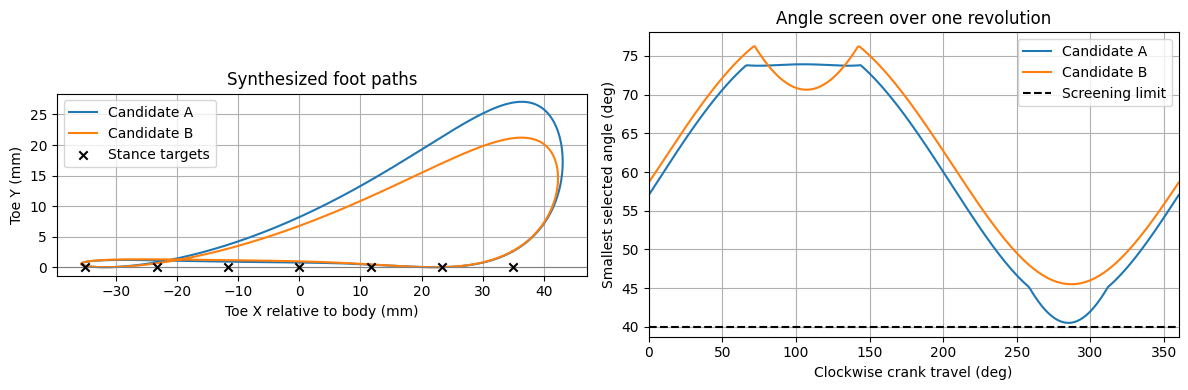

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for name, data in screens.items():
    toe = data["toe"]

    ax[0].plot(
        toe[:, 0], toe[:, 1],
        label=f"Candidate {name}"
    )

    ax[1].plot(
        GRID, data["angles"].min(axis=0),
        label=f"Candidate {name}"
    )

ax[0].scatter(
    TARGETS[:, 0], TARGETS[:, 1],
    marker="x", color="black",
    label="Stance targets", zorder=5
)
ax[0].axhline(0, color="gray", linewidth=0.8)
ax[0].set(
    xlabel="Toe X relative to body (mm)",
    ylabel="Toe Y (mm)",
    title="Synthesized foot paths"
)
ax[0].set_aspect("equal", adjustable="box")

ax[1].axhline(
    ANGLE_LIMIT_DEG,
    color="black", linestyle="--",
    label="Screening limit"
)
ax[1].set(
    xlabel="Clockwise crank travel (deg)",
    ylabel="Smallest selected angle (deg)",
    title="Angle screen over one revolution",
    xlim=(0, 360)
)

for axis in ax:
    axis.grid(True)
    axis.legend()

plt.tight_layout()
plt.show()

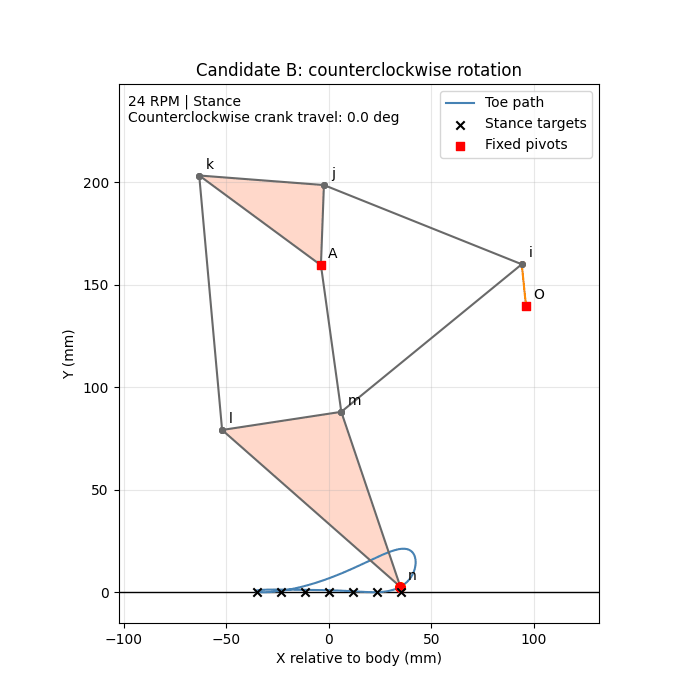

Saved Team1_animation2_CCW.gif
One cycle: 2.50 seconds


In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Polygon
from IPython.display import Image as IPImage, display

CHOSEN = "B"  # Use "B" to show candidate B.
v = candidates[CHOSEN].copy()

full_toe, full_angles, gaps, full_points = model(v, GRID)

assert gaps.max() < 1e-8, "This design cannot assemble."
assert full_angles.min() >= ANGLE_LIMIT_DEG - 1e-6

cycle_time_s = 60.0 / motor_rpm
n_frames = 50
fps = n_frames / cycle_time_s

frame_travel = np.linspace(
    0.0, 360.0, n_frames, endpoint=False
)

# Reverse the original clockwise motion.
model_travel = (-frame_travel) % 360.0
_, _, _, points = model(v, model_travel)

fig, ax = plt.subplots(figsize=(7, 7))
all_points = np.concatenate(list(full_points.values()), axis=0)

ax.set_xlim(
    all_points[:, 0].min() - 15,
    all_points[:, 0].max() + 15
)
ax.set_ylim(
    min(0.0, all_points[:, 1].min()) - 15,
    all_points[:, 1].max() + 15
)
ax.set_aspect("equal")
ax.set(
    xlabel="X relative to body (mm)",
    ylabel="Y (mm)",
    title=f"Candidate {CHOSEN}: counterclockwise rotation"
)
ax.grid(True, alpha=0.3)
ax.axhline(0, color="black", linewidth=1)

ax.plot(
    full_toe[:, 0], full_toe[:, 1],
    color="steelblue", label="Toe path"
)
ax.scatter(
    TARGETS[:, 0], TARGETS[:, 1],
    marker="x", color="black",
    label="Stance targets", zorder=5
)
ax.scatter(
    [points["O"][0, 0], points["A"][0, 0]],
    [points["O"][0, 1], points["A"][0, 1]],
    color="red", marker="s",
    label="Fixed pivots", zorder=6
)

lines = {
    key: ax.plot(
        [], [], "o-", color="dimgray", markersize=4
    )[0]
    for key in KEYS
}
lines["Oi"].set_color("darkorange")

triangles = []
for names in [("j", "A", "k"), ("l", "m", "n")]:
    patch = Polygon(
        [points[key][0] for key in names],
        facecolor="coral", alpha=0.3, edgecolor="none"
    )
    ax.add_patch(patch)
    triangles.append((names, patch))

labels = {
    name: ax.annotate(
        name, point[0],
        xytext=(5, 5), textcoords="offset points"
    )
    for name, point in points.items()
}

foot, = ax.plot([], [], "ro", markersize=7)
status = ax.text(
    0.02, 0.98, "",
    transform=ax.transAxes, va="top"
)
ax.legend(loc="upper right")


def update(frame):
    for key, line in lines.items():
        P = points[key[0]][frame]
        Q = points[key[1]][frame]
        line.set_data([P[0], Q[0]], [P[1], Q[1]])

    for names, patch in triangles:
        patch.set_xy([points[key][frame] for key in names])

    for name, label in labels.items():
        label.xy = points[name][frame]

    toe = points["n"][frame]
    foot.set_data([toe[0]], [toe[1]])

    phase = (
        "Stance"
        if model_travel[frame] <= STANCE_DEG
        else "Swing"
    )

    status.set_text(
        f"{motor_rpm:g} RPM | {phase}\n"
        f"Counterclockwise crank travel: "
        f"{frame_travel[frame]:.1f} deg"
    )


animation = FuncAnimation(
    fig, update,
    frames=n_frames,
    interval=1000 / fps
)

filename = "Team1_animation2_CCW.gif"
animation.save(filename, writer=PillowWriter(fps=fps))

plt.close(fig)
display(IPImage(filename=filename))

print(f"Saved {filename}")
print(f"One cycle: {cycle_time_s:.2f} seconds")